# Hito 2 · Wine: perfiles químicos y contexto vitivinícola

**Visualización de Datos · Grupo 3**

Medalit Nieves Salcedo Rodriguez · Max Alejandro Huaranja Montaño · Miguel Alexander Alviry Zapata

Docente: Natali Johana Velandia Fajardo · 18 de octubre de 2026

## Propósito y continuidad
Analista de laboratorio: comparar cultivares, revisar calidad/cobertura y priorizar mediciones antes de modelar. Continúa las decisiones D1–D5, preguntas Q1–Q6, seis KPI, paleta y wireframe A del Hito 1. Se añaden Q7–Q8 para redundancia y síntesis multivariante; Q9–Q10 incorporan contexto sectorial oficial. Las clases no son calidad comercial ni nombres de variedades.

## Reproducción
Python 3.12. Desde la carpeta del proyecto: `python -m pip install -r requirements.txt`; abra este cuaderno y ejecute todas las celdas en orden. No necesita claves ni AWS. Los CSV, Wine original y polígonos están incluidos. No se requiere red para calcular ni para las figuras estáticas. El panel Altair HTML carga bibliotecas JavaScript desde CDN al abrirse. La app se ejecuta con `python -m streamlit run app.py`.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from analisis import *
from figuras_estaticas import static_chart
df = load_wine()
oiv = load_oiv()
print('Wine:', df.shape, '| OIV:', oiv.shape)
display(df.head())

Wine: (178, 16) | OIV: (120, 4)


,id_muestra,clase,alcohol,acido_malico,cenizas,alcalinidad_cenizas,magnesio,fenoles_totales,flavonoides,fenoles_no_flavonoides,proantocianinas,intensidad_color,tonalidad,od280_od315,prolina,cultivar
0,1,1,14.23,1.71,2.43,15.6,127,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065,Cultivar 1
1,2,1,13.20,1.78,2.14,11.2,100,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050,Cultivar 1
2,3,1,13.16,2.36,2.67,18.6,101,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185,Cultivar 1
3,4,1,14.37,1.95,2.50,16.8,113,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480,Cultivar 1
4,5,1,13.24,2.59,2.87,21.0,118,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735,Cultivar 1


## Fuentes, granularidad y preparación
**Wine:** UCI, DOI 10.24432/C5PC7J, 178 muestras, 13 mediciones, tres cultivares de una misma región italiana. Sin fecha ni coordenadas por muestra. No se usa orden de fila como tiempo. `id_muestra` es un identificador técnico generado según el orden del archivo y no es predictor. Unidades no documentadas se conservan como escala original.

**OIV:** Statistical Brief, septiembre de 2025, tabla 15, p.14. Transcripción de 10 países, Otros y Mundo para 2015–2024; mhl = millones de hectolitros, excluidos mostos y jugos. Cifras redondeadas/revisables. Otros y Mundo no se mapean. **No hay unión entre Wine y OIV:** el componente geo-temporal es una ampliación contextual, no evidencia espacial ni temporal de los cultivares.

**Geometría:** Natural Earth, Admin 0 Countries, 1:110m, dominio público, GeoJSON local. La asignación por `ADM0_A3`/ISO3 se verifica para los diez países. No se geocodifican muestras.

La tabla Wine conserva todas las filas; se verifican dimensiones, clase, finitud, faltantes y duplicación exacta. La transcripción OIV conserva 120 observaciones país/agregado–año. Véase `data/procedencia.json` para fuentes y huellas SHA256.

In [2]:
assert len(df)==178 and len(FEATURES)==13
assert df[FEATURES].notna().all().all() and np.isfinite(df[FEATURES]).all().all()
assert set(df.clase)=={1,2,3}
assert not df.duplicated(['clase']+FEATURES).any()
assert not oiv.duplicated(['pais','anio']).any()
print('Validación: sin faltantes, infinitos ni duplicados exactos en Wine.')
display(pd.DataFrame([metrics(df)]))
display(bootstrap_ci(df))

Validación: sin faltantes, infinitos ni duplicados exactos en Wine.


,n,completeness,duplicates,balance,alcohol,max_eta
0,178,100.0,0.0,67.605634,13.000618,0.727775


,cultivar,n,media,inferior,superior
0,Cultivar 1,59,13.744746,13.624555,13.859835
1,Cultivar 2,71,12.278732,12.156757,12.407891
2,Cultivar 3,48,13.153750,13.003953,13.304583


## Diccionario semántico de indicadores
K1: filas completas/finitas con clase válida. K2: 100 × filas válidas / filas del alcance. K3: 100 × duplicados adicionales / filas del alcance (excluye identificador técnico). K4: 100 × menor n / mayor n de los cultivares seleccionados, contando ceros; no aplica con menos de dos cultivares. K5: media de alcohol del alcance. K6: mayor η² entre las 13 mediciones; no aplica con menos de dos grupos observados o varianza nula. Todos se recalculan tras filtros. Valores sin denominador o sin evidencia suficiente se muestran como No aplica; no se convierten a cero.

## 1. Q1 / D1 · Cobertura de grupos

**Pregunta:** ¿Cuántas muestras hay por cultivar?

**Elección visual:** Barras desde cero con n y porcentaje: comparación directa de cobertura.

**Lectura e implicación:** Hay 59, 71 y 48 muestras en los cultivares 1, 2 y 3. El balance mínimo/máximo es 67,6%; las frecuencias de esta colección no estiman prevalencia poblacional.

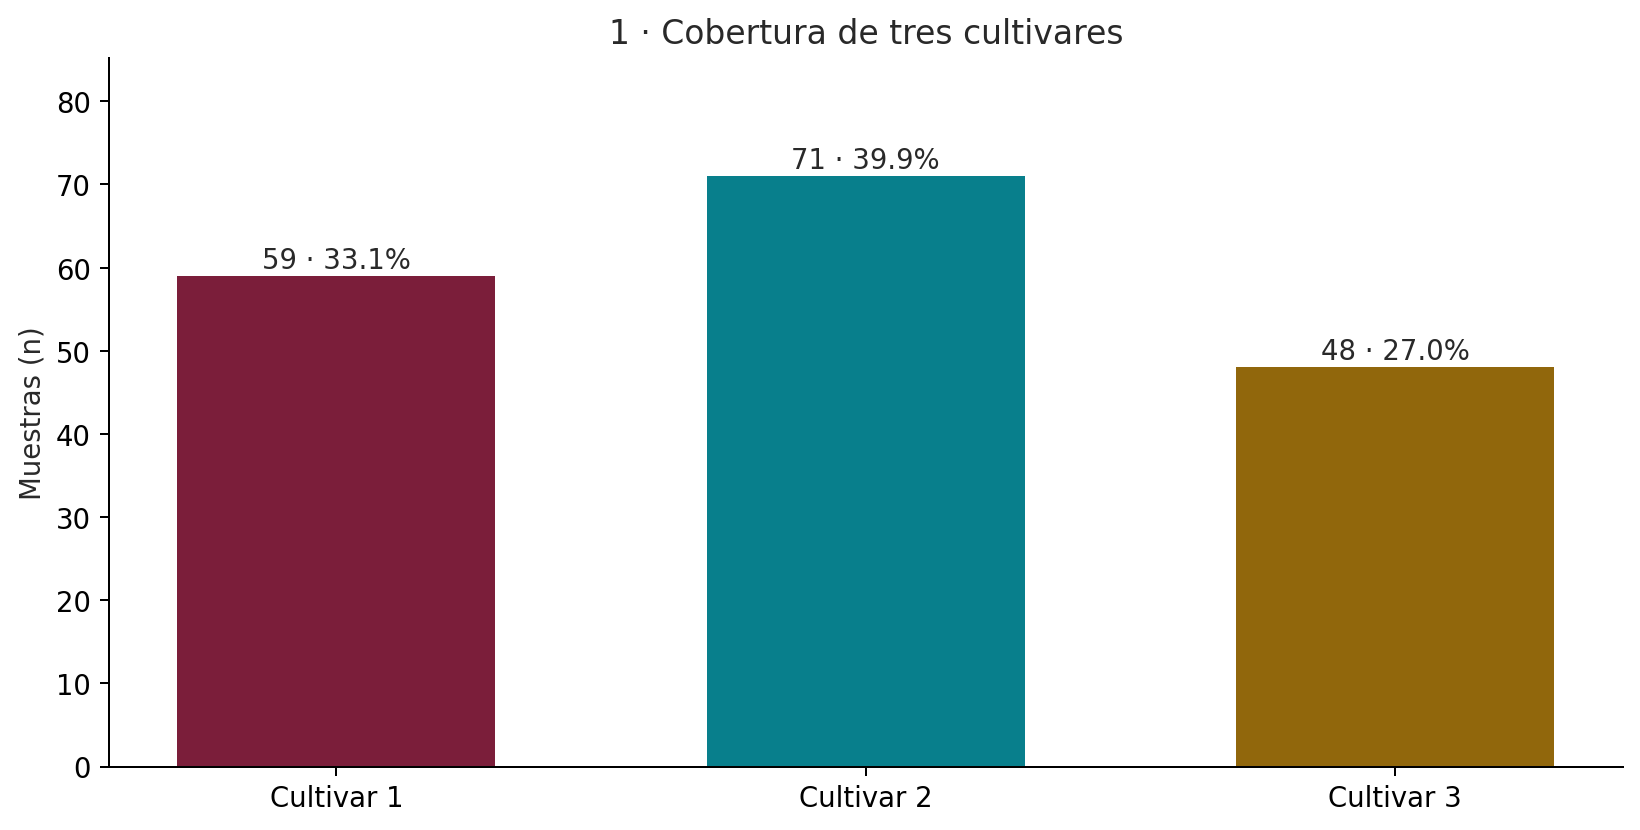

In [3]:
from IPython.display import Image
fig = static_chart(1, df, oiv)
(ROOT/'figuras').mkdir(exist_ok=True)
fig.savefig(ROOT/'figuras/01.png', bbox_inches='tight', dpi=180)
display(Image(filename=str(ROOT/'figuras/01.png')))
plt.close(fig)

## 2. Q2 / D4 · Distribución de flavonoides

**Pregunta:** ¿Cómo cambian mediana, dispersión y solapamiento?

**Elección visual:** Cajas y bigotes distinguen dispersión individual de precisión de medias.

**Lectura e implicación:** Medianas por cultivar: Cultivar 1: 2.98, Cultivar 2: 2.03, Cultivar 3: 0.69. Conviene comparar perfiles completos; una diferencia de centros no equivale a separación perfecta.

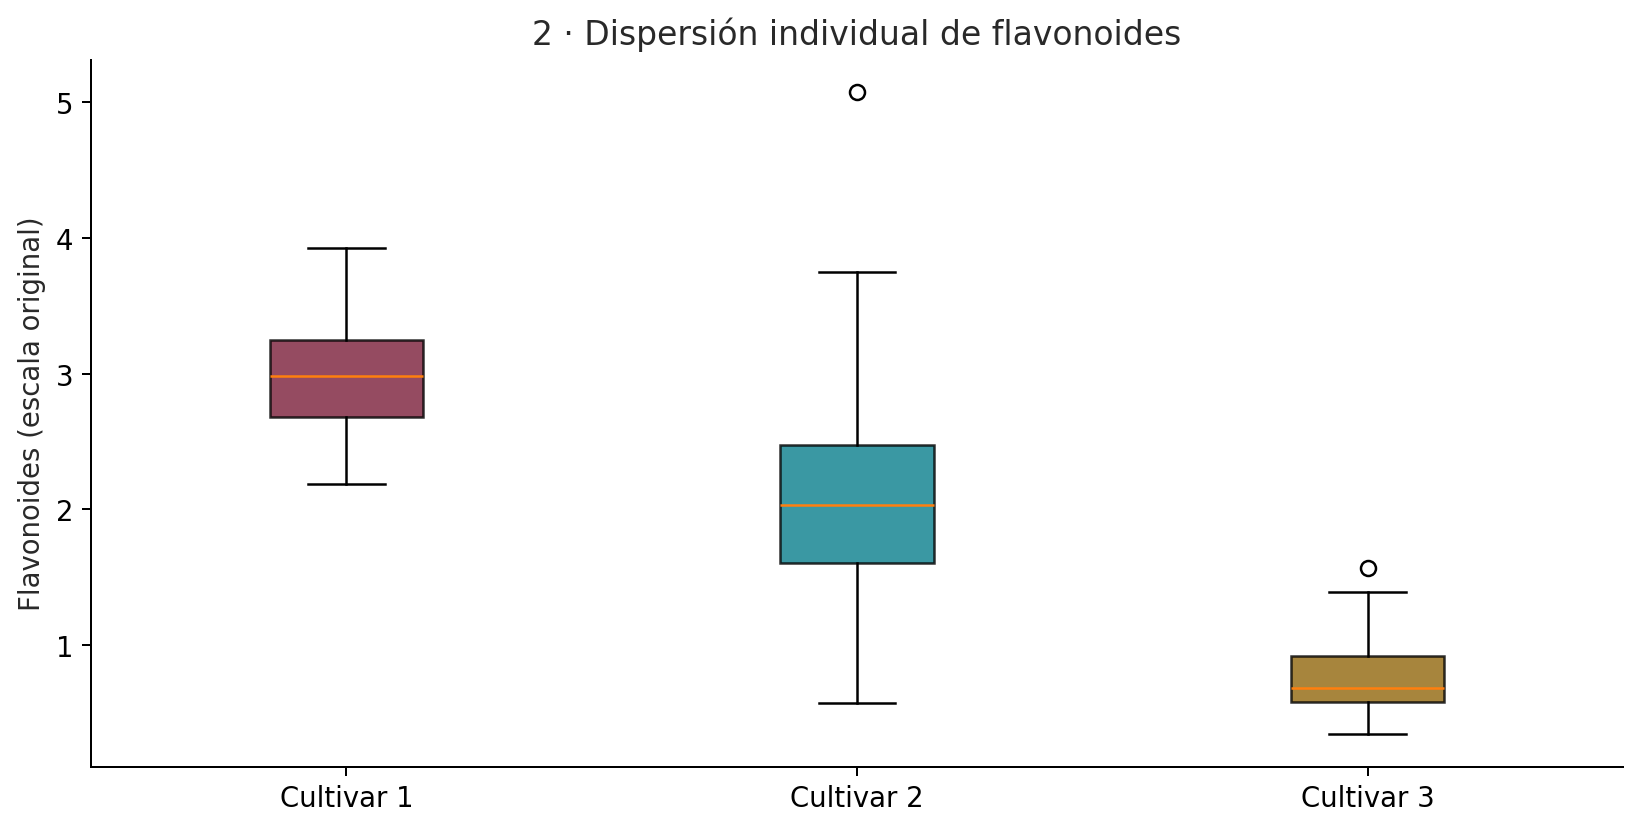

In [4]:
from IPython.display import Image
fig = static_chart(2, df, oiv)
(ROOT/'figuras').mkdir(exist_ok=True)
fig.savefig(ROOT/'figuras/02.png', bbox_inches='tight', dpi=180)
display(Image(filename=str(ROOT/'figuras/02.png')))
plt.close(fig)

## 3. Q3 / D3 · Alcohol y color

**Pregunta:** ¿Se mantiene la relación dentro de cada grupo?

**Elección visual:** Small multiples con ejes comunes reducen mezcla de grupos y facilitan comparación.

**Lectura e implicación:** Correlaciones dentro de grupos: Cultivar 1: r=0.41, Cultivar 2: r=0.27, Cultivar 3: r=0.35. La mezcla de grupos puede modificar la correlación global; no hay evidencia causal.

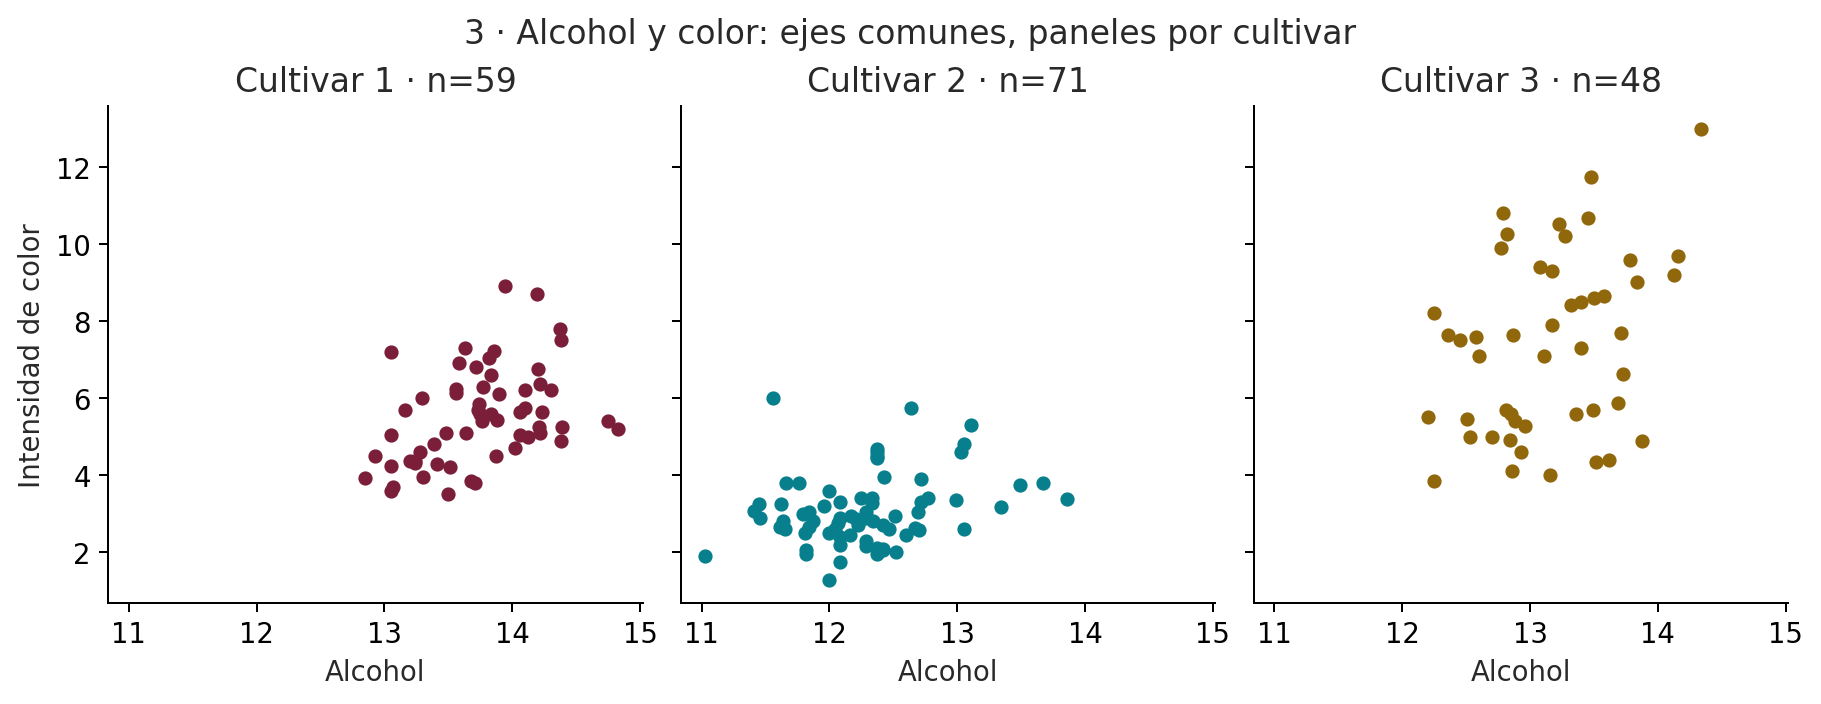

In [5]:
from IPython.display import Image
fig = static_chart(3, df, oiv)
(ROOT/'figuras').mkdir(exist_ok=True)
fig.savefig(ROOT/'figuras/03.png', bbox_inches='tight', dpi=180)
display(Image(filename=str(ROOT/'figuras/03.png')))
plt.close(fig)

## 4. Q4 / D5 · Incertidumbre de la media

**Pregunta:** ¿Con qué precisión se estima el alcohol medio por cultivar?

**Elección visual:** Punto e IC bootstrap percentil del 95%, 5.000 remuestras con reemplazo por grupo; semilla 42 + índice de grupo. No es un intervalo para observaciones individuales.

**Lectura e implicación:** Cultivar 1: media 13.745, IC [13.625, 13.860], n=59; Cultivar 2: media 12.279, IC [12.157, 12.408], n=71; Cultivar 3: media 13.154, IC [13.004, 13.305], n=48. El remuestreo supone observaciones intercambiables dentro de grupo; no corrige sesgo de selección, multiplicidad ni dependencia no registrada.

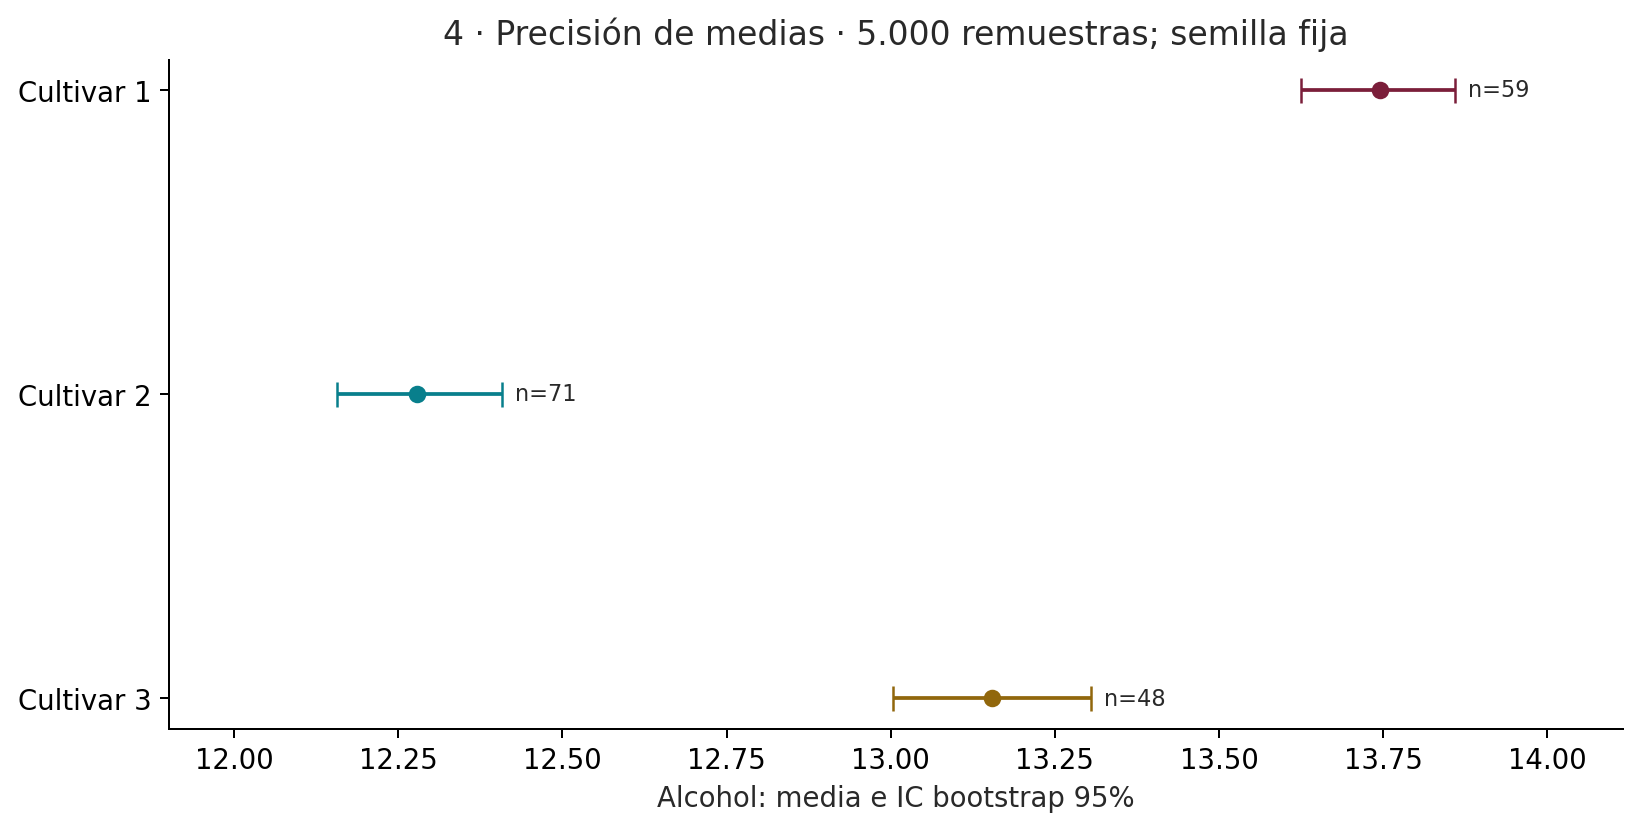

In [6]:
from IPython.display import Image
fig = static_chart(4, df, oiv)
(ROOT/'figuras').mkdir(exist_ok=True)
fig.savefig(ROOT/'figuras/04.png', bbox_inches='tight', dpi=180)
display(Image(filename=str(ROOT/'figuras/04.png')))
plt.close(fig)

## 5. Q5 / D2 · Selección exploratoria de mediciones

**Pregunta:** ¿Qué mediciones explican más variación entre medias de grupos?

**Elección visual:** Ranking de η² = SS entre grupos / SS total, adimensional y comparable entre escalas.

**Lectura e implicación:** Mayor separación: flavonoides (η²=0.728). Es una asociación descriptiva dentro de esta muestra; no reporta precisión de clasificación. Para modelar, seleccionar variables solo dentro del entrenamiento y validar aparte.

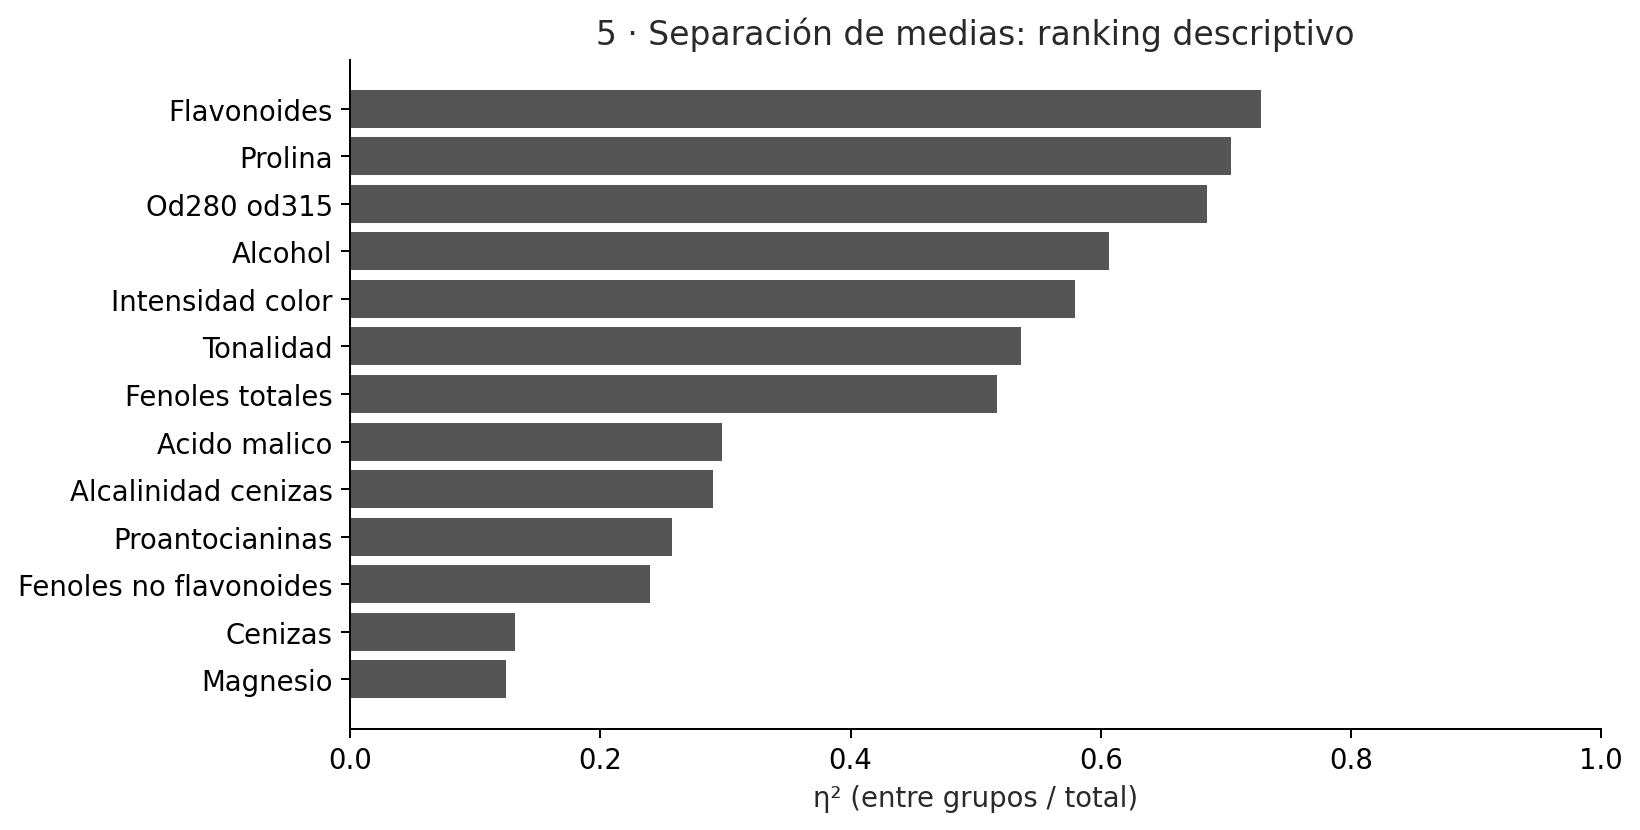

In [7]:
from IPython.display import Image
fig = static_chart(5, df, oiv)
(ROOT/'figuras').mkdir(exist_ok=True)
fig.savefig(ROOT/'figuras/05.png', bbox_inches='tight', dpi=180)
display(Image(filename=str(ROOT/'figuras/05.png')))
plt.close(fig)

## 6. Q6 / D4 · Distribución acumulada de prolina

**Pregunta:** ¿Difiere toda la distribución de prolina?

**Elección visual:** ECDF sin bins, estilos de línea y color redundantes; permite leer cuantiles.

**Lectura e implicación:** Medianas de prolina: Cultivar 1: 1095, Cultivar 2: 495, Cultivar 3: 628. El desplazamiento de curvas aporta información que una media aislada oculta; hay solapamiento en parte de los valores.

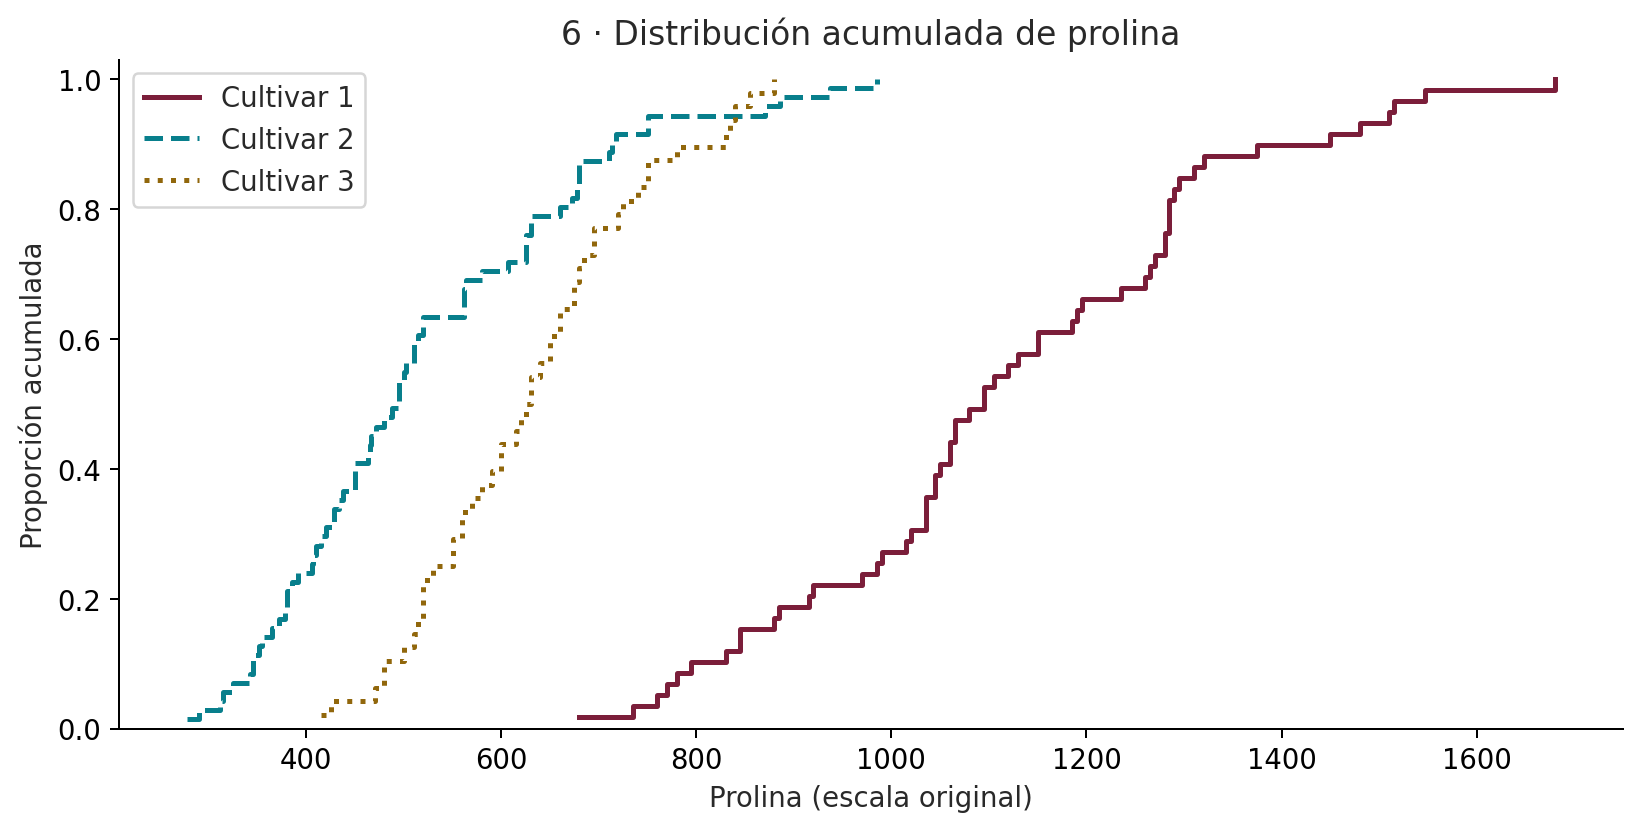

In [8]:
from IPython.display import Image
fig = static_chart(6, df, oiv)
(ROOT/'figuras').mkdir(exist_ok=True)
fig.savefig(ROOT/'figuras/06.png', bbox_inches='tight', dpi=180)
display(Image(filename=str(ROOT/'figuras/06.png')))
plt.close(fig)

## 7. Q7 / D3 · Redundancia global

**Pregunta:** ¿Qué pares químicos se relacionan más?

**Elección visual:** Mapa de calor de correlaciones de Pearson, escala fija [-1,1], simétrica respecto a cero.

**Lectura e implicación:** Fenoles totales y flavonoides: r=0.865. Pueden ser parcialmente redundantes. Correlación global puede reflejar las diferencias entre cultivares; revisar relación intragrupo y relaciones no lineales.

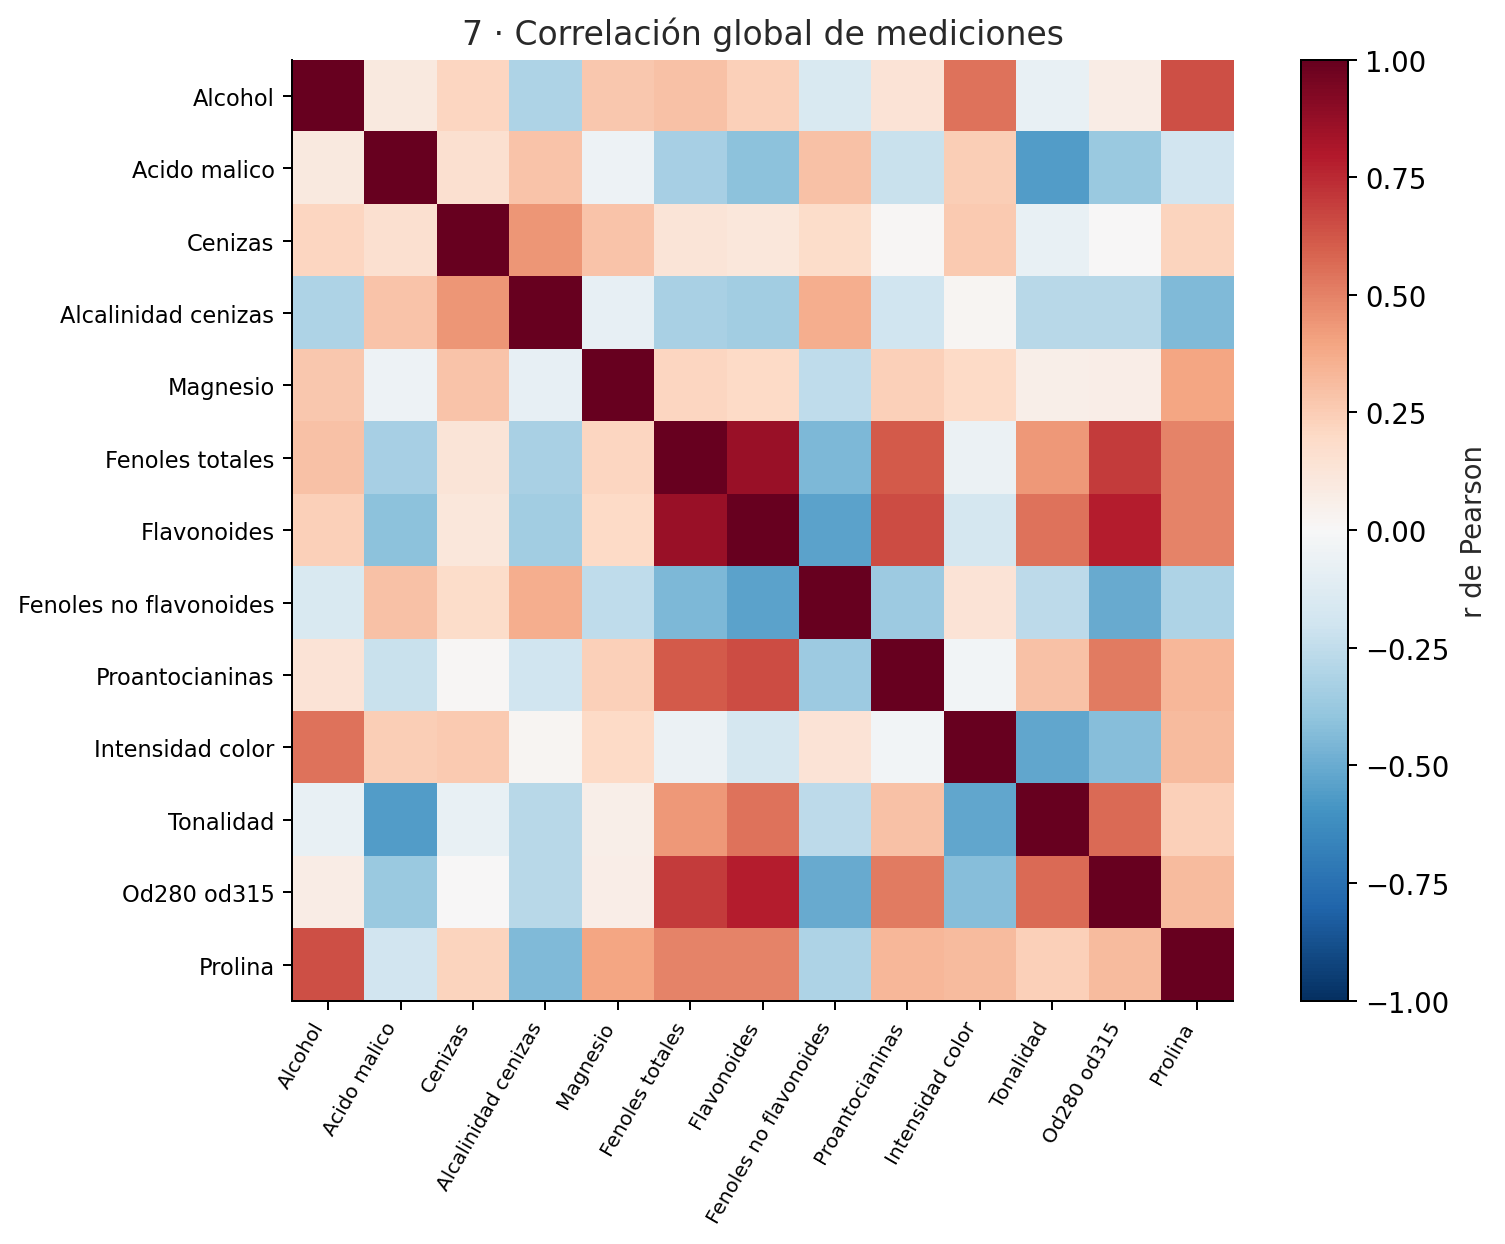

In [9]:
from IPython.display import Image
fig = static_chart(7, df, oiv)
(ROOT/'figuras').mkdir(exist_ok=True)
fig.savefig(ROOT/'figuras/07.png', bbox_inches='tight', dpi=180)
display(Image(filename=str(ROOT/'figuras/07.png')))
plt.close(fig)

## 8. Q8 / D2-D3 · Perfil multivariante

**Pregunta:** ¿Cómo se organiza la variación conjunta de 13 mediciones?

**Elección visual:** PCA tras centrar y estandarizar cada variable; SVD sin usar la etiqueta para calcular los componentes.

**Lectura e implicación:** CP1 y CP2 resumen 55.4% de la varianza estandarizada. La proyección sugiere estructura de grupos, pero omite variación y no constituye evaluación de un clasificador; los ejes carecen de unidades químicas.

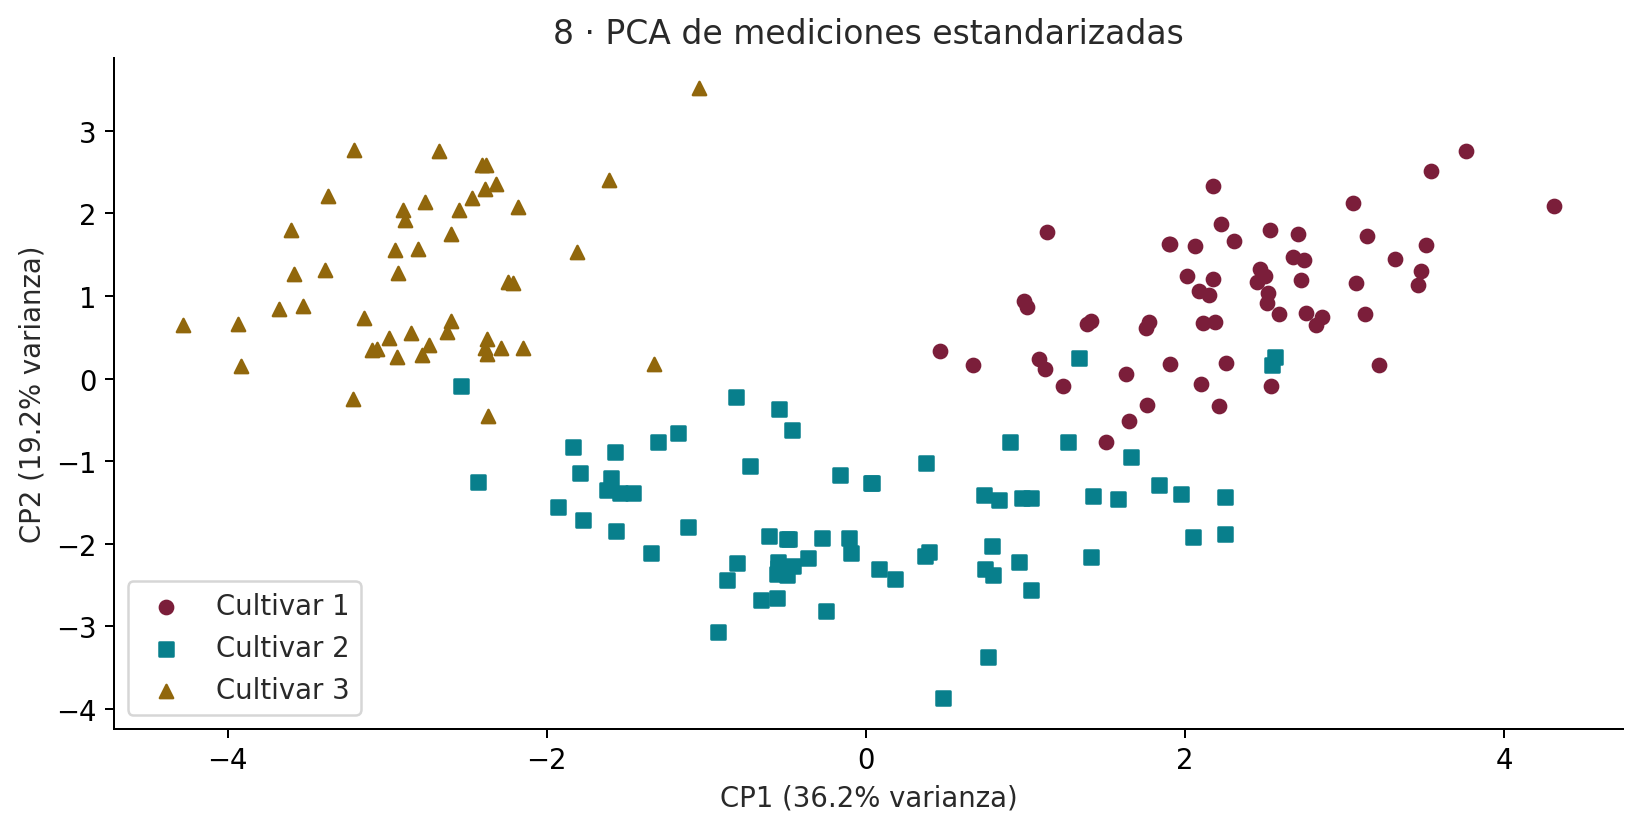

In [10]:
from IPython.display import Image
fig = static_chart(8, df, oiv)
(ROOT/'figuras').mkdir(exist_ok=True)
fig.savefig(ROOT/'figuras/08.png', bbox_inches='tight', dpi=180)
display(Image(filename=str(ROOT/'figuras/08.png')))
plt.close(fig)

## 9. Q9 / Contexto geográfico · Ampliación del Hito 1

**Pregunta:** ¿Dónde aumenta o disminuye la producción de vino?

**Elección visual:** Coropleta de cambio relativo 2023–2024; escala divergente fija ±30%, cero neutro. Países ISO3 vinculados a polígonos Natural Earth. Gris significa fuera de cobertura.

**Lectura e implicación:** Italia cambia +15.1% y Francia -22.8%. Diez países reúnen 82.7% del volumen mundial de 2024. Países grandes no equivalen a mayores tasas. Esta fuente es independiente de Wine; no localiza las muestras ni explica su composición.

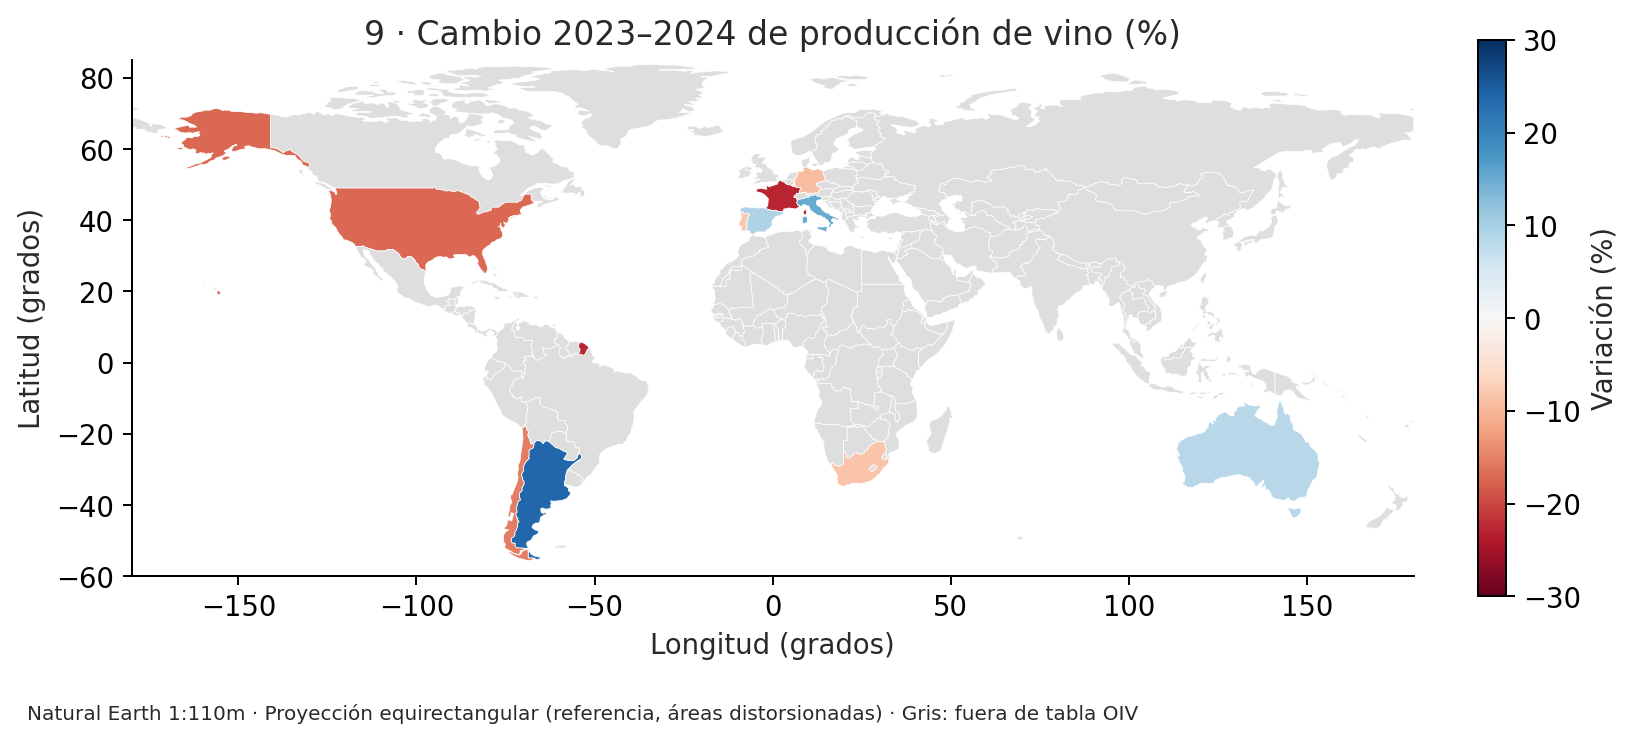

In [11]:
from IPython.display import Image
fig = static_chart(9, df, oiv)
(ROOT/'figuras').mkdir(exist_ok=True)
fig.savefig(ROOT/'figuras/09.png', bbox_inches='tight', dpi=180)
display(Image(filename=str(ROOT/'figuras/09.png')))
plt.close(fig)

In [12]:
display(geo_data(oiv)[['pais','iso3','produccion_mhl','anterior','cambio_pct']])
geo_ids = {f['properties']['ADM0_A3'] for f in json.loads((ROOT/'data/paises_natural_earth.geojson').read_text(encoding='utf-8'))['features']}
assert set(geo_data(oiv).iso3).issubset(geo_ids)
print('10 de 10 países con geometría; cero países sin correspondencia.')
display(chart_map_altair(oiv))

,pais,iso3,produccion_mhl,anterior,cambio_pct
9,Italia,ITA,44.1,38.3,15.143603
19,Francia,FRA,36.5,47.3,-22.832981
29,España,ESP,31.0,28.4,9.154930
39,Estados Unidos,USA,21.1,25.5,-17.254902
49,Argentina,ARG,10.9,8.8,23.863636
59,Australia,AUS,10.4,9.6,8.333333
69,Chile,CHL,9.3,11.0,-15.454545
79,Sudáfrica,ZAF,8.5,9.3,-8.602151
89,Alemania,DEU,7.8,8.6,-9.302326
99,Portugal,PRT,6.9,7.5,-8.000000


10 de 10 países con geometría; cero países sin correspondencia.


alt.Chart(...)

## 10. Q10 / Contexto temporal · Ampliación del Hito 1

**Pregunta:** ¿Es estable la producción de los principales productores?

**Elección visual:** Líneas anuales con marcadores, eje vertical desde cero; datos 2015–2024, sin interpolar años ausentes.

**Lectura e implicación:** Italia pasa de 50,0 a 44,1 mhl entre 2015 y 2024; Francia de 47,8 a 36,5 y España de 37,7 a 31,0. Las series fluctúan: no describen un descenso monótono ni permiten atribuir causas. El año de producción no es el año de publicación del informe (2025).

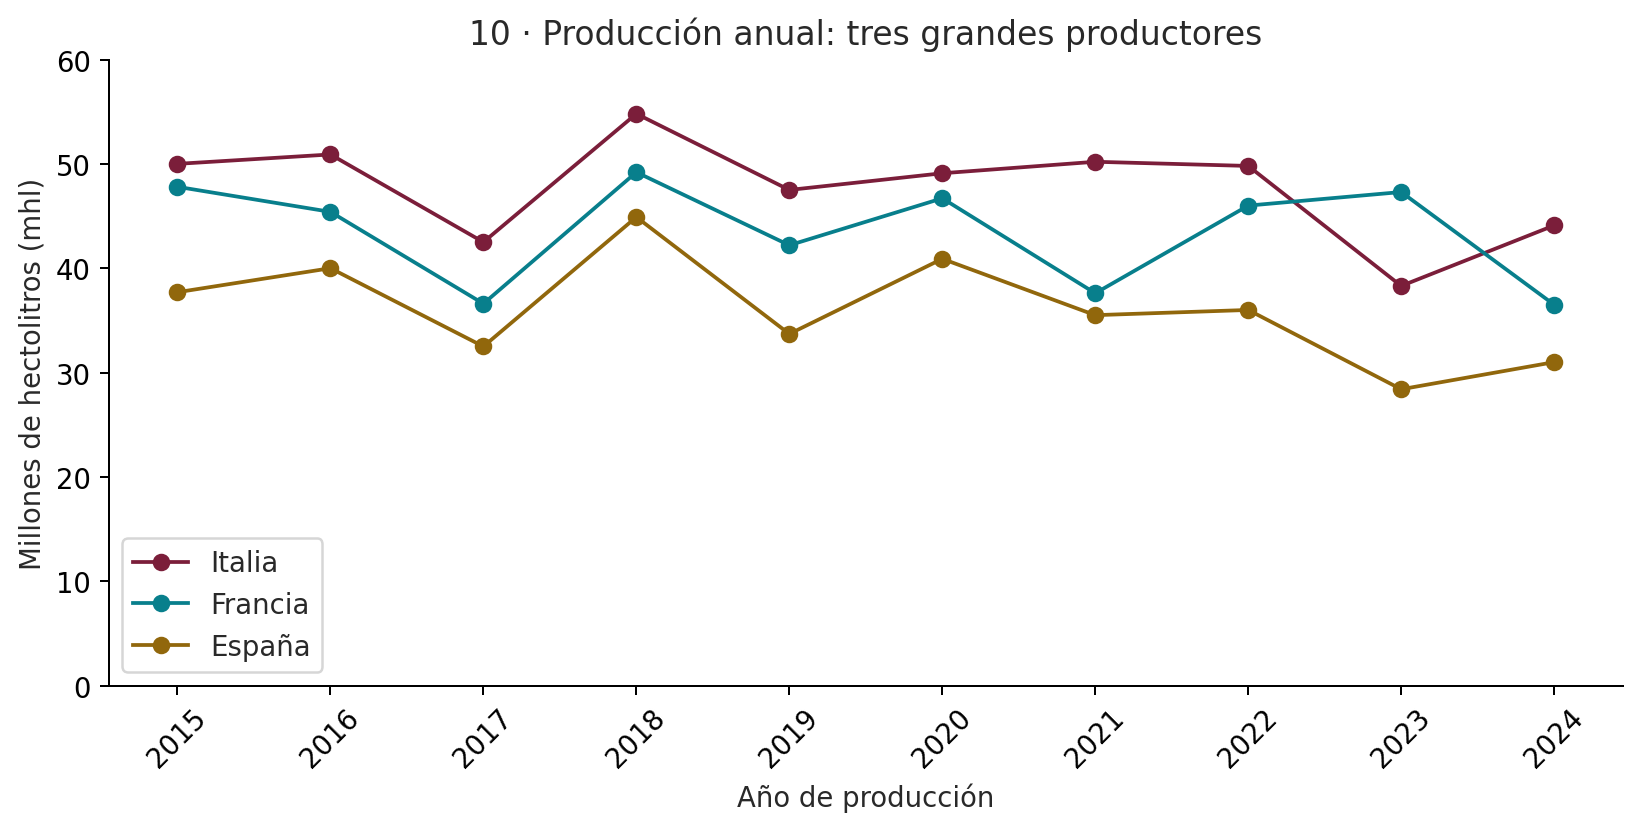

In [13]:
from IPython.display import Image
fig = static_chart(10, df, oiv)
(ROOT/'figuras').mkdir(exist_ok=True)
fig.savefig(ROOT/'figuras/10.png', bbox_inches='tight', dpi=180)
display(Image(filename=str(ROOT/'figuras/10.png')))
plt.close(fig)

## Panel declarativo: cuatro vistas conectadas
Seleccione un rectángulo en la dispersión; la cobertura, la caja y la media se recalculan para esa región. Clic en la leyenda filtra cultivar; Mayús+clic permite múltiples; doble clic en el panel restablece el pincel. Se conserva color fijo por grupo. El panel usa la misma tabla a nivel muestra; no une la tabla OIV. El IC bootstrap se interpreta en la visualización 4 y la app; la cuarta vista de este panel muestra solo la media.

In [14]:
panel = linked_panel(df)
panel.save(str(ROOT/'Panel_4_vistas.html'))
display(panel)

alt.VConcatChart(...)

## Streamlit: traducción del wireframe A
Página Laboratorio: filtros horizontales, seis KPI, cuatro vistas conectadas mediante filtros (cobertura, dispersión, caja e IC), interpretaciones, detalle y descarga CSV. Página Contexto: tres KPI sectoriales, año del mapa y países de la serie; dos gráficos. Se mantienen la jerarquía calidad → cobertura → relación → dispersión/precisión y la paleta del Hito 1.

El selector de área evita sobrecargar una sola pantalla y distingue granularidades. Las vistas químicas se actualizan con cada cambio de cultivo/rango; los filtros del contexto no afectan a las muestras. Etiquetas, símbolos y títulos complementan el color. Botones nativos y controles etiquetados permiten interacción por teclado. No se afirma una auditoría completa WCAG.

**Ficha de despliegue y URL real:** consultar `README.md` y el informe, actualizados después de verificar la publicación. Un servidor local no equivale a despliegue público.

In [15]:
# Casos analíticos de borde y reproducibilidad
assert len(filter_wine(df,[GROUPS[0]]))==59
assert metrics(filter_wine(df,[]))['n']==0
assert bootstrap_ci(df).equals(bootstrap_ci(df))
assert np.isnan(metrics(df[df.clase==1])['max_eta'])
print('Casos de borde analíticos aprobados. Para verificar la app: python pruebas.py')

Casos de borde analíticos aprobados. Para verificar la app: python pruebas.py


## Síntesis, límites y siguientes decisiones
1. La colección presenta diferente cobertura entre cultivares; revisar n antes de generalizar.
2. Flavonoides, prolina y alcohol aportan contraste descriptivo; estudiar redundancias y validar variables sin fuga de información.
3. Los IC cuantifican variación de remuestreo, no representatividad ni certeza del clasificador. La selección visual posterior a mirar datos vuelve exploratorias las comparaciones.
4. PCA resume parte de la variación; no reporta desempeño predictivo.
5. El contexto OIV permite un mapa y una serie reales; no convierte Wine en un estudio geográfico ni longitudinal. Un futuro estudio químico por región/año requeriría una fuente con trazabilidad muestral.

## Referencias
- UCI Machine Learning Repository. Wine. https://archive.ics.uci.edu/dataset/109/wine (CC BY 4.0).
- OIV. (2025, septiembre). *OIV Statistical Brief: Wine, Table Grapes & Dried Grapes in 2024*, tabla 15, p.14. https://www.oiv.int/sites/default/files/documents/OIV_Statistical_Brief-Wine_Table_Grapes_and_Dried_Grapes_in_2024_0.pdf
- Natural Earth. Admin 0 Countries, 1:110m. https://www.naturalearthdata.com/downloads/110m-cultural-vectors/110m-admin-0-countries/ ; GeoJSON: https://github.com/nvkelso/natural-earth-vector/blob/master/geojson/ne_110m_admin_0_countries.geojson
- Especificación y wireframe del Hito1 del grupo incluidos en `docs/`.

Se utilizó asistencia de Codex para programación, documentación y validación. Las interpretaciones se restringen a fuentes y cálculos reproducibles; el grupo debe revisar y comprender la entrega.